# Mandatory number 2
Date: 9.11.2026

Dataset: QSAR Toxicity

Course: STK-IN4300  

Name: Esther Zijerveld

In [186]:
# Import necessary libraries
%matplotlib inline

# Dataframes and arrays
import pandas as pd
import numpy as np

# For scientific programming
import scipy

# For machine learning
import sklearn
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from pygam import LinearGAM, s


# Plotting
import matplotlib.pyplot as plt


The history saving thread hit an unexpected error (OperationalError('database or disk is full')).History will not be written to the database.


In [187]:
# Data comes from QSAR toxicity
data = pd.read_csv("data/qsar_aquatic_toxicity.csv", sep=";")
data.columns = ["TPSA", "SAacc", "H050", "MLOGP", "RDCHI", "GATS1p", "nN", "C040", "LC50"]

In [188]:
data.head()

,TPSA,SAacc,H050,MLOGP,RDCHI,GATS1p,nN,C040,LC50
0,0.00,0.000,0,2.638,1.401,0.632,0,0,4.330
1,9.23,11.000,0,5.799,2.930,0.486,0,0,7.019
2,9.23,11.000,0,5.453,2.887,0.495,0,0,6.723
3,9.23,11.000,0,4.068,2.758,0.695,0,0,5.979
4,215.34,327.629,3,0.189,4.677,1.333,0,4,6.064


In [189]:
data.describe()

,TPSA,SAacc,H050,MLOGP,RDCHI,GATS1p,nN,C040,LC50
count,545.000000,545.000000,545.000000,545.000000,545.000000,545.00000,545.000000,545.000000,545.000000
mean,48.561872,58.977035,0.939450,2.313299,2.494624,1.04696,1.005505,0.354128,4.660106
std,46.760699,68.182392,1.619619,1.743392,0.809925,0.40372,1.397860,0.807426,1.666279
min,0.000000,0.000000,0.000000,-6.446000,1.000000,0.28100,0.000000,0.000000,0.122000
25%,15.790000,11.000000,0.000000,1.228000,1.975000,0.73700,0.000000,0.000000,3.601000
50%,40.460000,42.683000,0.000000,2.273000,2.344000,1.02100,1.000000,0.000000,4.530000
75%,70.140000,77.727000,1.000000,3.395000,2.913000,1.26700,2.000000,0.000000,5.610000
max,347.320000,571.952000,18.000000,9.148000,6.439000,2.50000,11.000000,11.000000,10.047000


In [190]:
X = data.loc[:, "TPSA" : "C040"]
y = data[:]["LC50"]
X["intercept"] = 1

X.head()

,TPSA,SAacc,H050,MLOGP,RDCHI,GATS1p,nN,C040,intercept
0,0.00,0.000,0,2.638,1.401,0.632,0,0,1
1,9.23,11.000,0,5.799,2.930,0.486,0,0,1
2,9.23,11.000,0,5.453,2.887,0.495,0,0,1
3,9.23,11.000,0,4.068,2.758,0.695,0,0,1
4,215.34,327.629,3,0.189,4.677,1.333,0,4,1


### (a) Fit linear regression models
split into training and test

(i) model count variables as a linear effect

(ii) binary-code each count predictor as 0 if absent and 1 if present

In [191]:
X_binary = X.copy()
X_binary.iloc[:, [2, 6, 7]] = np.where(X_binary.iloc[:, [2, 6, 7]] > 0, 1, 0)
print(X_binary.head())




X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42)

X_train_bin, X_test_bin, y_train, y_test = train_test_split(
    X_binary, y, test_size=0.33, random_state=42)



     TPSA    SAacc  H050  MLOGP  RDCHI  GATS1p  nN  C040  intercept
0    0.00    0.000     0  2.638  1.401   0.632   0     0          1
1    9.23   11.000     0  5.799  2.930   0.486   0     0          1
2    9.23   11.000     0  5.453  2.887   0.495   0     0          1
3    9.23   11.000     0  4.068  2.758   0.695   0     0          1
4  215.34  327.629     1  0.189  4.677   1.333   0     1          1


Standardise the data

In [192]:
from sklearn.preprocessing import StandardScaler


std_scaler = StandardScaler()
X_train_sc = std_scaler.fit_transform(X_train)
X_test_sc = std_scaler.transform(X_test)
X_train_bin_sc = std_scaler.fit_transform(X_train_bin)
X_test_bin_sc = std_scaler.transform(X_test_bin)
X_train_sc = pd.DataFrame(X_train_sc)
X_test_sc = pd.DataFrame(X_test_sc)
X_train_bin_sc = pd.DataFrame(X_train_bin_sc)
X_test_bin_sc = pd.DataFrame(X_test_bin_sc)


#print(X_train_sc[:5][:])
#y_train_sc = std_scaler.fit_transform(y_train)
#y_test_sc = std_scaler.transform(y_test)

Fit two separate regression models

In [ ]:
from sklearn.linear_model import LinearRegression

# Initialising the linear regression model
reg = LinearRegression()

# Fitting to the training data
reg.fit(X_train_sc, y_train)

print("R^2: ", reg.score(X_test_sc, y_test))

# Prediction on test set
y_pred = reg.predict(X_test_sc)
y_pred_train = reg.predict(X_train_sc)

# Calculating the RMSE
err = np.sqrt((1/len(y_pred))*np.sum((y_pred - y_test)**2))
err_train = np.sqrt((1/len(y_pred_train))*np.sum((y_pred_train - y_train)**2))
print("RMSE: ", err)
print("MSE: ", err**2)
print("RMSE train: ", err_train)
print("MSE train: ", err_train**2)


R^2:  0.5035650972102842
RMSE:  1.155642629042809
MSE:  1.3355098860609755
RMSE train:  1.2161397090130235
MSE train:  1.4789957918382814


In [ ]:
reg = LinearRegression()

reg.fit(X_train_bin_sc, y_train)
print("R^2: ", reg.score(X_test_bin_sc, y_test))

y_pred = reg.predict(X_test_bin_sc)
y_pred_train = reg.predict(X_train_bin_sc)

err_train = np.sqrt((1/len(y_pred_train))*np.sum((y_pred_train - y_train)**2))
err = np.sqrt(1/len(y_pred)*np.sum((y_pred - y_test)**2))

print("RMSE: ", err)
print("MSE: ", err**2)
print("RMSE train: ", err_train)
print("MSE train: ", err_train**2)



R^2:  0.4947903927657775
RMSE:  1.1658111375850426
MSE:  1.3591156085173313
RMSE train:  1.241719885186616
MSE train:  1.5418682732678628


Option (ii) shows slightly higher RMSE error on the test set.

### Results and interpretation

The split contains 365 training and 180 test observations. In option (i), H050, nN, and C040 enter as linear count effects. In option (ii), each count predictor is binary-coded as 0 if the count is zero and 1 if it is positive; this is not full dummy encoding of every count level. The difference in test error is small, with option (i) slightly lower on this split.


### (b) Repeat 200 times with different splits

Mean test errors over 200 paired splits:


test_MSE                 test_RMSE          \
                                  mean     std  median      mean     std   
model                                                                      
Binary-coded counts (0 vs >0)   1.5317  0.1717  1.5224    1.2357  0.0693   
Linear count effects            1.4794  0.1711  1.4822    1.2143  0.0705   

                                      train_MSE                 train_RMSE  \
                               median      mean     std  median       mean   
model                                                                        
Binary-coded counts (0 vs >0)  1.2338    1.4711  0.0827  1.4794     1.2124   
Linear count effects           1.2175    1.4189  0.0818  1.4254     1.1907   

                                               
                                  std  median  
model                                          
Binary-coded counts (0 vs >0)  0.0342  1.2163  
Linear count effects           0.0344  1.1939

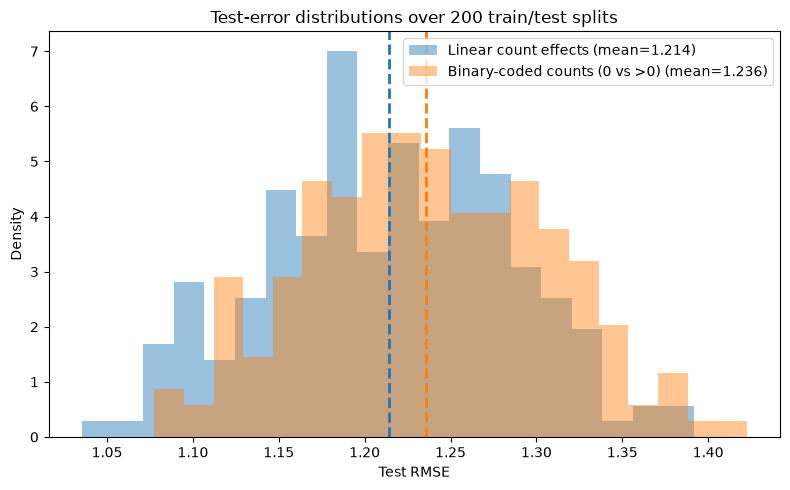

In [196]:
count_columns = ["H050", "nN", "C040"]

n_repeats = 200
repeated_errors = []

for split_seed in range(n_repeats):
    # Train_test split
    X_train_rep, X_test_rep, y_train_rep, y_test_rep = train_test_split(
        X, y, test_size=0.33, random_state=split_seed
    )

    # Option (i): fit with the count variables as numeric linear effects.
    model_linear = LinearRegression().fit(X_train_rep, y_train_rep)
    pred_linear = model_linear.predict(X_test_rep)
    pred_linear_train = model_linear.predict(X_train_rep)

    # Option (ii): encode each count as 0 if absent and 1 if present.
    X_train_rep_bin = X_train_rep.copy()
    X_test_rep_bin = X_test_rep.copy()
    X_train_rep_bin.loc[:, count_columns] = (
        X_train_rep_bin.loc[:, count_columns] > 0
    ).astype(int)
    X_test_rep_bin.loc[:, count_columns] = (
        X_test_rep_bin.loc[:, count_columns] > 0
    ).astype(int)

    model_bin = LinearRegression().fit(X_train_rep_bin, y_train_rep)
    pred_bin = model_bin.predict(X_test_rep_bin)
    pred_bin_train = model_bin.predict(X_train_rep_bin)

    for model_name, prediction, train_prediction in [
        ("Linear count effects", pred_linear, pred_linear_train),
        ("Binary-coded counts (0 vs >0)", pred_bin, pred_bin_train),
    ]:
        mse = mean_squared_error(y_test_rep, prediction)
        mse_train = mean_squared_error(y_train_rep, train_prediction)
        repeated_errors.append(
            {
                "split": split_seed,
                "model": model_name,
                "test_MSE": mse,
                "test_RMSE": np.sqrt(mse),
                "train_MSE": mse_train,
                "train_RMSE": np.sqrt(mse_train),
            }
        )

repeated_errors = pd.DataFrame(repeated_errors)
repeated_error_summary = repeated_errors.groupby("model")[
    ["test_MSE", "test_RMSE", "train_MSE", "train_RMSE"]
].agg(["mean", "std", "median"])
print("Mean test errors over 200 paired splits:")
display(repeated_error_summary.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
for model_name, color in [
    ("Linear count effects", "tab:blue"),
    ("Binary-coded counts (0 vs >0)", "tab:orange"),
]:
    errors = repeated_errors.loc[
        repeated_errors["model"] == model_name, "test_RMSE"
    ]
    ax.hist(
        errors,
        bins=20,
        density=True,
        alpha=0.45,
        color=color,
        label=f"{model_name} (mean={errors.mean():.3f})",
    )
    ax.axvline(errors.mean(), color=color, linestyle="--", linewidth=2)

ax.set_xlabel("Test RMSE")
ax.set_ylabel("Density")
ax.set_title("Test-error distributions over 200 train/test splits")
ax.legend()
fig.tight_layout()
plt.show()


### Results and interpretation

The 200 repetitions use paired 67/33 splits. Option (i), with linear count effects, has mean test MSE 1.4794 (SD 0.1711) and mean test RMSE 1.2143 (SD 0.0705). Option (ii) codes each count as 0 if absent and 1 if present; it has mean test MSE 1.5317 (SD 0.1717) and mean test RMSE 1.2357 (SD 0.0693). Thus the binary-coded model has higher average error and split-to-split variability in these repetitions.

The figure shows empirical test-RMSE distributions; dashed lines mark the two means. A binary indicator combines all positive count levels into one group, so it cannot represent differences in response across those positive counts.

A single train/test split can give a noisy and split-dependent estimate of prediction performance: an unusually easy or difficult test set can change the ranking of the models. Repeating the split makes that variability visible and gives a more stable comparison for this dataset and split procedure.


## (C) Apply variable selection procedures 
Forward and backward selection with different stopping criteria: Akaike Information Criterion (AIC), Bayesian Information Criterion (BIC):

$$AIC= -2\log(L) + 2k, \qquad BIC= -2\log(L) + k\log(n)$$

Here $L$ is the maximised likelihood, $k$ is the number of estimated parameters (including the intercept), and $n$ is the training sample size. Both criteria trade off fit and model complexity; BIC penalises extra parameters more strongly for this sample size.

Forward selection starts with an intercept-only model and adds the predictor that most decreases the chosen criterion, stopping when no addition improves it. Backward selection starts with all predictors and removes the predictor that most decreases the criterion, stopping when no removal improves it. Selection uses the training split only; the selected models are evaluated on the held-out test split.

On the 67/33 split from (a), forward and backward AIC both select TPSA, SAacc, MLOGP, RDCHI, GATS1p, and nN (AIC=1192.8). Forward BIC selects MLOGP, TPSA, SAacc, and nN (BIC=1221), while backward BIC selects the same six predictors as AIC (BIC=1220). Forward BIC stops at a local solution: no single next addition improves BIC there, even though a different six-predictor model has a lower BIC. This illustrates that greedy forward/backward selection need not find the global optimum. All four selected models exclude H050 and C040, which are both count variables.

In [ ]:
def forward_selection(X, y, criterion="AIC"):

    # Start with intercept-only model
    selected = []
    remaining = list(X.columns)

    if criterion not in ["AIC", "BIC"]:
        raise ValueError("criterion must be 'AIC' or 'BIC'")

    # Calculate AIC or BIC
    def get_score(variables):
        X_model = sm.add_constant(X[variables])
        model = sm.OLS(y, X_model).fit()

        if criterion == "AIC":
            return model.aic
        else:
            return model.bic

    current_score = get_score(selected)

    while remaining:

        scores = {}

        # Try adding each remaining variable
        for variable in remaining:
            candidate = selected + [variable]
            scores[variable] = get_score(candidate)

        # Find variable giving the lowest criterion
        best_variable = min(scores, key=scores.get)
        best_score = scores[best_variable]

        # Stop if adding a variable does not improve the criterion
        if best_score >= current_score:
            break

        # Add the variable
        selected.append(best_variable)
        remaining.remove(best_variable)

        current_score = best_score

        print(
            f"Added: {best_variable}, "
            f"{criterion}: {current_score:.3f}"
            f"MSE"
        )

    # Fit final model
    final_X = sm.add_constant(X[selected])
    final_model = sm.OLS(y, final_X).fit()

    return final_model, selected

In [113]:
# Run forward selection
final_model, selected_variables = forward_selection(X_train, y_train)

# Display selected variables
print("\nSelected variables:")
print(selected_variables)

# Display final regression results
print(final_model.summary())

Added: MLOGP, AIC: 1297.791
Added: TPSA, AIC: 1246.478
Added: SAacc, AIC: 1212.647
Added: nN, AIC: 1201.909
Added: RDCHI, AIC: 1198.382
Added: GATS1p, AIC: 1192.875

Selected variables:
['MLOGP', 'TPSA', 'SAacc', 'nN', 'RDCHI', 'GATS1p']
                            OLS Regression Results                            
Dep. Variable:                   LC50   R-squared:                       0.468
Model:                            OLS   Adj. R-squared:                  0.459
Method:                 Least Squares   F-statistic:                     52.41
Date:                Mon, 09 Nov 2026   Prob (F-statistic):           3.56e-46
Time:                        12:53:06   Log-Likelihood:                -589.44
No. Observations:                 365   AIC:                             1193.
Df Residuals:                     358   BIC:                             1220.
Df Model:                           6                                         
Covariance Type:            nonrobust              

In [112]:
# Run forward selection
final_model, selected_variables = forward_selection(X_train, y_train, "BIC")

# Display selected variables
print("\nSelected variables:")
print(selected_variables)

# Display final regression results
print(final_model.summary())

Added: MLOGP, BIC: 1305.591
Added: TPSA, BIC: 1258.177
Added: SAacc, BIC: 1228.246
Added: nN, BIC: 1221.409

Selected variables:
['MLOGP', 'TPSA', 'SAacc', 'nN']
                            OLS Regression Results                            
Dep. Variable:                   LC50   R-squared:                       0.448
Model:                            OLS   Adj. R-squared:                  0.442
Method:                 Least Squares   F-statistic:                     73.12
Date:                Mon, 09 Nov 2026   Prob (F-statistic):           2.66e-45
Time:                        12:51:34   Log-Likelihood:                -595.95
No. Observations:                 365   AIC:                             1202.
Df Residuals:                     360   BIC:                             1221.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t     

In [114]:
def backward_selection(X, y, criterion="AIC"):

    # Start with all explanatory variables
    selected = list(X.columns)
    #print(selected)

    if criterion not in ["AIC", "BIC"]:
        raise ValueError("criterion must be 'AIC' or 'BIC'")

    # Calculate AIC or BIC
    def get_score(variables):
        X_model = sm.add_constant(X[variables])
        model = sm.OLS(y, X_model).fit()

        if criterion == "AIC":
            return model.aic
        else:
            return model.bic

    current_score = get_score(selected)

    while len(selected) > 0:

        scores = {}

        # Try removing each remaining variable
        for variable in selected:
            candidate = [v for v in selected if v != variable]
            scores[variable] = get_score(candidate)

        # Find variable giving the lowest criterion
        worst_variable = min(scores, key=scores.get)
        best_score = scores[worst_variable]

        # Stop if removing a variable does not improve the criterion
        if best_score >= current_score:
            break

        # Remove the variable
        selected.remove(worst_variable)
        current_score = best_score

        print(
            f"Removed: {worst_variable}, "
            f"{criterion}: {current_score:.3f}"
        )

    # Fit final model
    final_X = sm.add_constant(X[selected])
    final_model = sm.OLS(y, final_X).fit()

    return final_model, selected

In [ ]:
# Run backward selection
final_model, selected_variables = backward_selection(X_train, y_train)

# Display selected variables
print("\nSelected variables:")
print(selected_variables)

# Display final regression results
print(final_model.summary())

Removed: H050, AIC: 1194.757
Removed: C040, AIC: 1192.875

Selected variables:
['TPSA', 'SAacc', 'MLOGP', 'RDCHI', 'GATS1p', 'nN', 'intercept']
                            OLS Regression Results                            
Dep. Variable:                   LC50   R-squared:                       0.468
Model:                            OLS   Adj. R-squared:                  0.459
Method:                 Least Squares   F-statistic:                     52.41
Date:                Mon, 09 Nov 2026   Prob (F-statistic):           3.56e-46
Time:                        12:54:08   Log-Likelihood:                -589.44
No. Observations:                 365   AIC:                             1193.
Df Residuals:                     358   BIC:                             1220.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025

In [ ]:
# Run backward selection
final_model, selected_variables = backward_selection(X_train, y_train, "BIC")

# Display selected variables
print("\nSelected variables:")
print(selected_variables)

# Display final regression results
print(final_model.summary())

Removed: H050, BIC: 1225.957
Removed: C040, BIC: 1220.175

Selected variables:
['TPSA', 'SAacc', 'MLOGP', 'RDCHI', 'GATS1p', 'nN', 'intercept']
                            OLS Regression Results                            
Dep. Variable:                   LC50   R-squared:                       0.468
Model:                            OLS   Adj. R-squared:                  0.459
Method:                 Least Squares   F-statistic:                     52.41
Date:                Mon, 09 Nov 2026   Prob (F-statistic):           3.56e-46
Time:                        12:53:53   Log-Likelihood:                -589.44
No. Observations:                 365   AIC:                             1193.
Df Residuals:                     358   BIC:                             1220.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025

The BIC penalised forward selection includes less variables in the final model because the BIC criterion penalises additional variables more. For backward selection both AIC and BIC include the same variables.

## (d) Ridge regression
Use a bootstrap out-of-bag (OOB) procedure and cross-validation (CV) to select the complexity parameter from a grid for ridge regression. Predictors are standardized within each fit; the response remains in its original units. The test split is reserved for final evaluation.

In [ ]:
# Candidate ridge penalty strengths; standardization is fitted within each training fold/sample.
lambdas = np.logspace(-4, 4, 41)

def ridge_model(alpha):
    return make_pipeline(StandardScaler(), 
                        Ridge(alpha=alpha))

In [198]:
# Use the same 67/33 split as part (a), keeping the test set out of tuning.
X_ridge = data.loc[:, "TPSA":"C040"]
y_ridge = data["LC50"]
X_ridge_train, X_ridge_test, y_ridge_train, y_ridge_test = train_test_split(
    X_ridge, y_ridge, test_size=0.33, random_state=42
)

# Bootstrap estimate: evaluate each fit on the observations left out of its resample.
B = 300 
n_train = len(y_ridge_train)
rng = np.random.default_rng(42)
bootstrap_mse = np.empty((len(lambdas), B))
print(np.shape(bootstrap_mse))

for b in range(B):
    # Selecting random samples within the train set of equal number to the size of the train set
    train_idx = rng.integers(0, n_train, size=n_train)
    in_bag = np.zeros(n_train, dtype=bool)
    in_bag[train_idx] = True
    oob_idx = np.flatnonzero(~in_bag)

    X_boot = X_ridge_train.iloc[train_idx].to_numpy(dtype=float)
    y_boot = y_ridge_train.iloc[train_idx].to_numpy(dtype=float)
    # Out of bag
    X_oob = X_ridge_train.iloc[oob_idx].to_numpy(dtype=float)
    y_oob = y_ridge_train.iloc[oob_idx].to_numpy(dtype=float)

    # Standardize within this resample, then solve the ridge path by eigendecomposition.
    x_mean = X_boot.mean(axis=0)
    x_scale = X_boot.std(axis=0)
    x_scale = np.where(x_scale == 0, 1.0, x_scale)
    Z_boot = (X_boot - x_mean) / x_scale
    Z_oob = (X_oob - x_mean) / x_scale
    y_mean = y_boot.mean()
    y_centered = y_boot - y_mean
    eigenvalues, eigenvectors = np.linalg.eigh(Z_boot.T @ Z_boot)
    projected_response = eigenvectors.T @ Z_boot.T @ y_centered

    for alpha_index, alpha in enumerate(lambdas):
        coefficients = eigenvectors @ (
            projected_response / (eigenvalues + alpha)
        )
        y_prediction = y_mean + Z_oob @ coefficients
        bootstrap_mse[alpha_index, b] = mean_squared_error(y_oob, y_prediction)

bootstrap_mean_mse = bootstrap_mse.mean(axis=1)
bootstrap_se_mse = bootstrap_mse.std(axis=1, ddof=1)
best_alpha_bootstrap = lambdas[np.argmin(bootstrap_mean_mse)]


# Evaluate the tuning choices once on the held-out test data.
ridge_bootstrap_final = ridge_model(best_alpha_bootstrap).fit(
    X_ridge_train, y_ridge_train
)
bootstrap_test_mse = mean_squared_error(
    y_ridge_test, ridge_bootstrap_final.predict(X_ridge_test)
)
bootstrap_train_mse = mean_squared_error(
    y_ridge_train, ridge_bootstrap_final.predict(X_ridge_train)
)

(41, 300)


In [199]:
# Five-fold CV on training data only; the pipeline standardizes inside each fold.
cv = KFold(n_splits=5, shuffle=True, random_state=42)
ridge_cv = GridSearchCV(
    ridge_model(alpha=1.0),
    param_grid={"ridge__alpha": lambdas},
    scoring="neg_mean_squared_error",
    cv=cv,
    refit=True,
    n_jobs=1,
)
ridge_cv.fit(X_ridge_train, y_ridge_train)
cv_mean_mse = -ridge_cv.cv_results_["mean_test_score"]
cv_std_mse = ridge_cv.cv_results_["std_test_score"]
best_alpha_cv = ridge_cv.best_params_["ridge__alpha"]


cv_test_mse = mean_squared_error(
    y_ridge_test, ridge_cv.predict(X_ridge_test)
)
cv_train_mse = mean_squared_error(
    y_ridge_train, ridge_cv.predict(X_ridge_train)
)

,best_alpha,estimated_training_MSE,test_MSE,test_RMSE,train_MSE,train_RMSE
tuning_method,,,,,,
Bootstrap OOB,3.9811,1.6150,1.3296,1.1531,1.4826,1.1531
5-fold CV,2.5119,1.5828,1.3306,1.1535,1.4806,1.2168


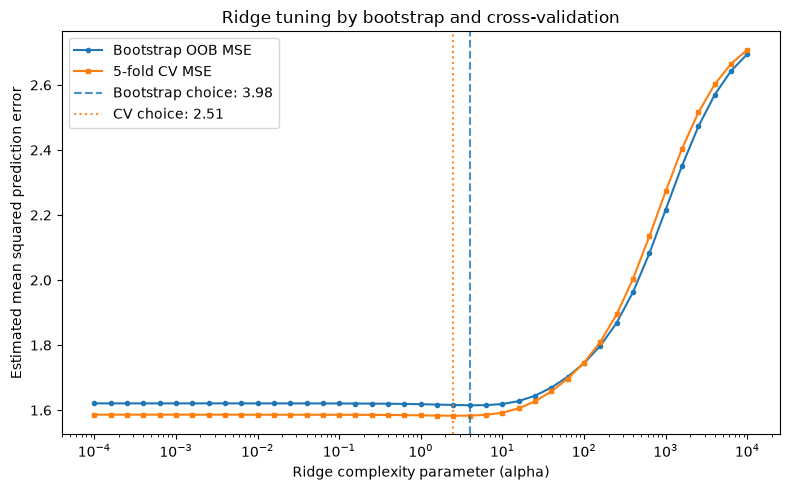

In [200]:
ridge_summary = pd.DataFrame(
    [
        {
            "tuning_method": "Bootstrap OOB",
            "best_alpha": best_alpha_bootstrap,
            "estimated_training_MSE": bootstrap_mean_mse.min(),
            "test_MSE": bootstrap_test_mse,
            "test_RMSE": np.sqrt(bootstrap_test_mse),
            "train_MSE": bootstrap_train_mse,
            "train_RMSE": np.sqrt(bootstrap_test_mse),
        },
        {
            "tuning_method": "5-fold CV",
            "best_alpha": best_alpha_cv,
            "estimated_training_MSE": cv_mean_mse.min(),
            "test_MSE": cv_test_mse,
            "test_RMSE": np.sqrt(cv_test_mse),
            "train_MSE": cv_train_mse,
            "train_RMSE": np.sqrt(cv_train_mse),
        },
    ]
).set_index("tuning_method")
display(ridge_summary.round(4))

# Plot estimated prediction error across the candidate alpha grid.
fig, ax = plt.subplots(figsize=(8, 5))
ax.semilogx(lambdas, bootstrap_mean_mse, marker="o", ms=3, label="Bootstrap OOB MSE")
ax.semilogx(lambdas, cv_mean_mse, marker="s", ms=3, label="5-fold CV MSE")
ax.axvline(best_alpha_bootstrap, color="tab:blue", linestyle="--", alpha=0.8,
           label=f"Bootstrap choice: {best_alpha_bootstrap:.3g}")
ax.axvline(best_alpha_cv, color="tab:orange", linestyle=":", alpha=0.9,
           label=f"CV choice: {best_alpha_cv:.3g}")
ax.set_xlabel("Ridge complexity parameter (alpha)")
ax.set_ylabel("Estimated mean squared prediction error")
ax.set_title("Ridge tuning by bootstrap and cross-validation")
ax.legend()
fig.tight_layout()
plt.show()

### Tuning notes

The bootstrap resamples the training observations with replacement and estimates prediction error on the corresponding out-of-bag observations (OOB). Five-fold cross-validation uses shuffled folds. For both approaches, the standardization step is inside the ridge pipeline to prevent information from validation observations leaking into scaling. The grid-search selection uses only the training split; the held-out test errors are not used to select alpha. The two error curves can differ because bootstrap OOB fits typically use fewer distinct training observations than a five-fold CV fit. 

### (e) Fit a Generalised Additive Model

Fit Generalised Additive Model (GAMs) to the QSAR aquatic toxicity data, using smoothing splines for continuous predictors and factor terms for the count predictors H050, nN, and C040. Compare two smoothing levels ($\lambda$ 0.1 and 10) and visualize selected predictor effects. $\lambda$ = 0.1 means less smoothing while $\lambda$= 10 means more smoothing.


In [179]:
from pygam import LinearGAM, f, s
from sklearn.model_selection import train_test_split

# Use all eight QSAR predictors; smooth continuous descriptors and treat counts as factors.
gam_feature_names = ["TPSA", "SAacc", "H050", "MLOGP", "RDCHI", "GATS1p", "nN", "C040"]

X_gam = data[gam_feature_names].to_numpy(dtype=float)
y_gam = data["LC50"].to_numpy(dtype=float)

X_gam_train, X_gam_test, y_gam_train, y_gam_test = train_test_split(
    X_gam, y_gam, test_size=0.2, random_state=42
)

# "H050", "nN" and "C040" are count variables.
gam_terms = s(0) + s(1) + f(2) + s(3) + s(4) + s(5) + f(6) + f(7)

# Compare a less- and more-smoothed fit
gam_low = LinearGAM(gam_terms, lam=0.1).fit(X_gam_train, y_gam_train)
gam_high = LinearGAM(gam_terms, lam=10).fit(X_gam_train, y_gam_train)

In [203]:
from sklearn.metrics import mean_squared_error, r2_score

predictions_low = gam_low.predict(X_gam_test)
predictions_high = gam_high.predict(X_gam_test)
pred_low_train = gam_low.predict(X_gam_train)
pred_high_train = gam_high.predict(X_gam_train)

for name, predictions, pred_train in [
    ("Lower smoothing (lambda=0.1)", predictions_low, pred_low_train),
    ("Higher smoothing (lambda=10)", predictions_high, pred_high_train),
]:
    mse = mean_squared_error(y_gam_test, predictions)
    mse_train = mean_squared_error(y_gam_train, pred_train)
    r2 = r2_score(y_gam_test, predictions)
    r2_train = r2_score(y_gam_train, pred_train)
    print(f"{name}: test MSE={mse:.4f}, test R2={r2:.4f}, train MSE={mse_train:.4f}")


Lower smoothing (lambda=0.1): test MSE=1.4666, test R2=0.4018, train MSE=1.0674
Higher smoothing (lambda=10): test MSE=1.4193, test R2=0.4211, train MSE=1.2326


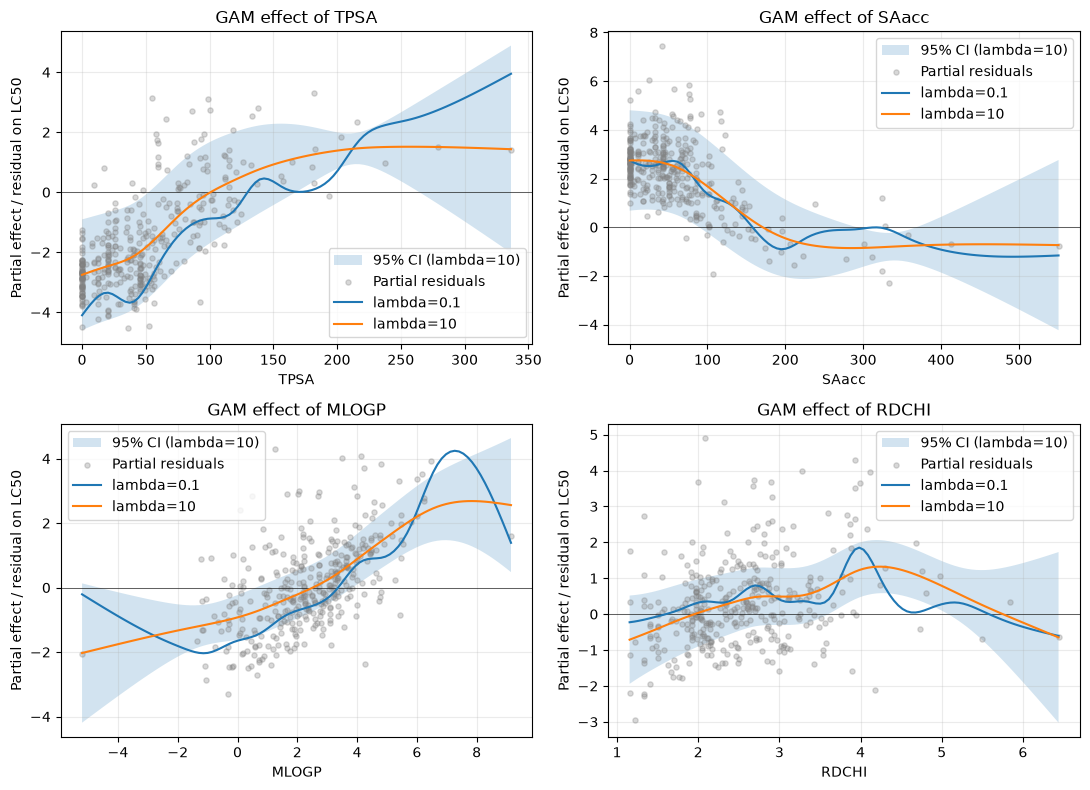

In [166]:
import matplotlib.pyplot as plt

# Plot partial effects and partial residuals for selected continuous predictors.
# Partial residuals adjust observed LC50 for the other fitted GAM terms.
plot_variables = ["TPSA", "SAacc", "MLOGP", "RDCHI"]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, name in zip(axes.flat, plot_variables):
    term_index = gam_feature_names.index(name)
    grid = gam_low.generate_X_grid(term=term_index, n=100)
    effect_low = gam_low.partial_dependence(term=term_index, X=grid)
    effect_high, confidence = gam_high.partial_dependence(
        term=term_index, X=grid, width=0.95
    )
    observed_effect = gam_high.partial_dependence(
        term=term_index, X=X_gam_train
    )
    partial_residuals = (
        y_gam_train - gam_high.predict(X_gam_train) + observed_effect
    )

    ax.fill_between(
        grid[:, term_index], confidence[:, 0], confidence[:, 1],
        alpha=0.2, label="95% CI (lambda=10)"
    )
    ax.scatter(
        X_gam_train[:, term_index], partial_residuals,
        s=14, alpha=0.3, color="gray", label="Partial residuals", zorder=2
    )
    ax.plot(grid[:, term_index], effect_low, label="lambda=0.1", zorder=3)
    ax.plot(grid[:, term_index], effect_high, label="lambda=10", zorder=3)
    ax.axhline(0, color="black", linewidth=0.7, alpha=0.6)
    ax.set_xlabel(name)
    ax.set_ylabel("Partial effect / residual on LC50")
    ax.set_title(f"GAM effect of {name}")
    ax.legend()
    ax.grid(alpha=0.25)

fig.tight_layout()
plt.show()


On this 66/33 split, the more-smoothed GAM (lambda=10) had a lower test MSE (1.4193) than the less-smoothed GAM (lambda=0.1; 1.4666), with test R2 values of 0.4211 and 0.4018, respectively. This is evidence for this split only; repeated splits or cross-validation would be needed to compare generalisation reliably. The effect plots show each selected variable's estimated additive contribution to LC50, with the 95% confidence band shown for lambda=10.


### (f) Regression tree
Fit a model using a regression tree. Draw the tree and report how the
cost-complexity pruning led to the selected tree size.


Candidate ccp_alpha values: 312
Selected ccp_alpha: 0.062374
Minimum 5-fold CV MSE: 2.0716
Unpruned tree: 356 leaves, depth 20
Selected tree: 11 leaves, 21 total nodes, depth 5
Test MSE: 1.5586; test R2: 0.4206; Train MSE: 1.2309; Train R2: 0.5572


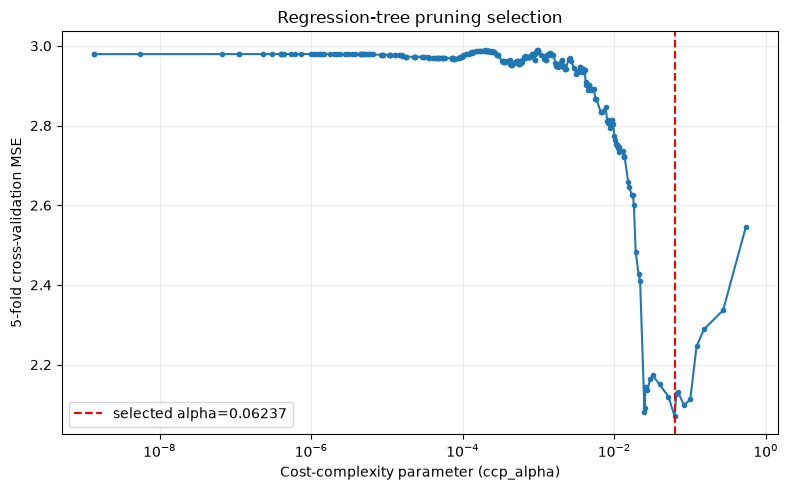

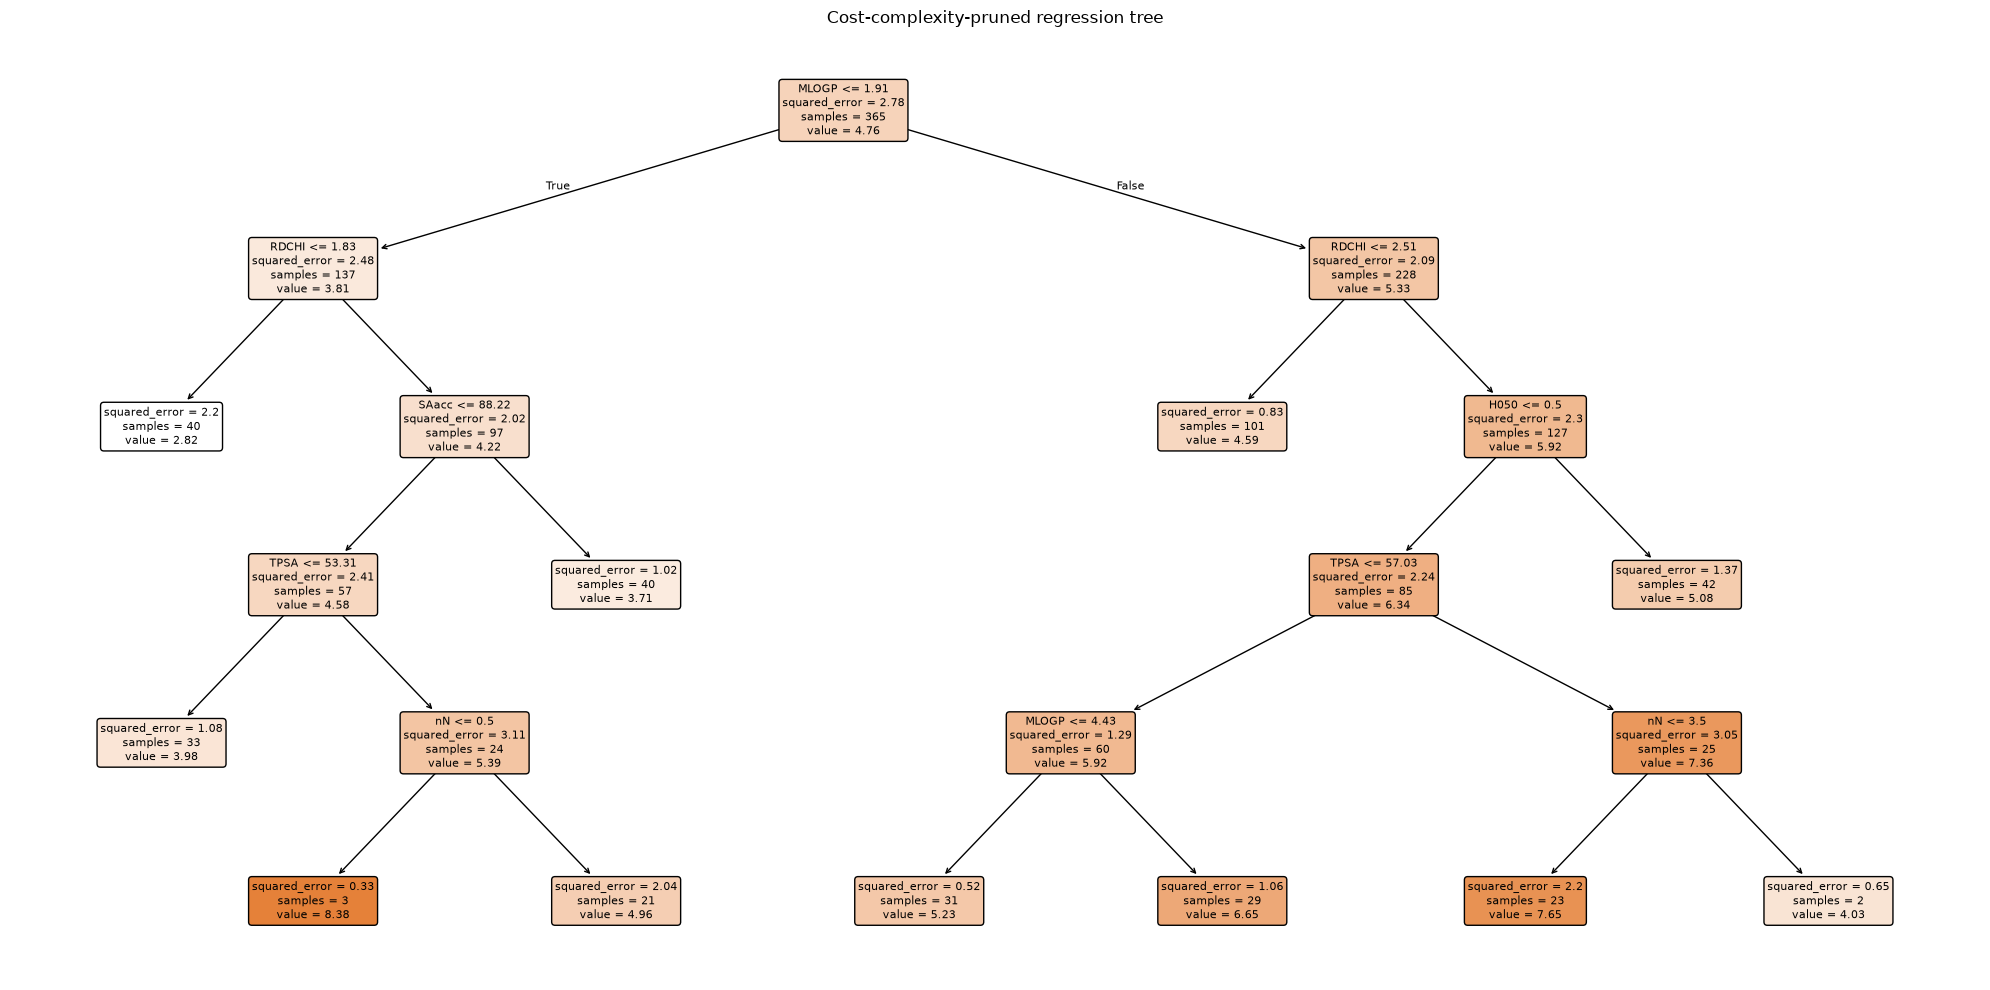

In [208]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.tree import DecisionTreeRegressor, plot_tree

# Use all eight predictors and the same 67/33 split as part (a).
tree_feature_names = ["TPSA", "SAacc", "H050", "MLOGP", "RDCHI", "GATS1p", "nN", "C040"]
X_tree = data[tree_feature_names]
y_tree = data["LC50"]
# Train-test split
X_tree_train, X_tree_test, y_tree_train, y_tree_test = train_test_split(
    X_tree, y_tree, test_size=0.33, random_state=42
)

# Generate candidate pruning values from the training set only.
unpruned_tree = DecisionTreeRegressor(random_state=42)
pruning_path = unpruned_tree.cost_complexity_pruning_path(
    X_tree_train, y_tree_train
)

# Using cross-validation to find the optimal cost-complexity pruning
ccp_alphas = np.unique(pruning_path.ccp_alphas[pruning_path.ccp_alphas >= 0])
#print(ccp_alphas)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_mse = []

for alpha in ccp_alphas:
    candidate = DecisionTreeRegressor(
        random_state=42, ccp_alpha=float(alpha)
    )
    fold_scores = cross_val_score(
        candidate, X_tree_train, y_tree_train,
        cv=cv, scoring="neg_mean_squared_error"
    )
    cv_mse.append(-fold_scores.mean())

best_alpha_index = int(np.argmin(cv_mse))
best_ccp_alpha = float(ccp_alphas[best_alpha_index])
tree_model = DecisionTreeRegressor(
    random_state=42, ccp_alpha=best_ccp_alpha
).fit(X_tree_train, y_tree_train)

print(f"Candidate ccp_alpha values: {len(ccp_alphas)}")
print(f"Selected ccp_alpha: {best_ccp_alpha:.6f}")
print(f"Minimum 5-fold CV MSE: {cv_mse[best_alpha_index]:.4f}")
unpruned_tree.fit(X_tree_train, y_tree_train)
print(
    f"Unpruned tree: {unpruned_tree.get_n_leaves()} leaves, "
    f"depth {unpruned_tree.get_depth()}"
)
print(
    f"Selected tree: {tree_model.get_n_leaves()} leaves, "
    f"{tree_model.tree_.node_count} total nodes, depth {tree_model.get_depth()}"
)
print(
    f"Test MSE: {mean_squared_error(y_tree_test, tree_model.predict(X_tree_test)):.4f}; "
    f"test R2: {r2_score(y_tree_test, tree_model.predict(X_tree_test)):.4f}; "
    f'Train MSE: {mean_squared_error(y_tree_train, tree_model.predict(X_tree_train)):.4f}; '
    f'Train R2: {r2_score(y_tree_train, tree_model.predict(X_tree_train)):.4f}'
)

# Plot cross-validation error along the pruning path.
fig, ax = plt.subplots(figsize=(8, 5))
positive_alphas = ccp_alphas > 0
ax.plot(ccp_alphas[positive_alphas], np.asarray(cv_mse)[positive_alphas], marker=".")
ax.axvline(best_ccp_alpha, color="red", linestyle="--", label=f"selected alpha={best_ccp_alpha:.4g}")
ax.set_xscale("log")
ax.set_xlabel("Cost-complexity parameter (ccp_alpha)")
ax.set_ylabel("5-fold cross-validation MSE")
ax.set_title("Regression-tree pruning selection")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

# Draw the selected, pruned regression tree.
fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(
    tree_model, feature_names=tree_feature_names,
    filled=True, rounded=True, precision=2, fontsize=8, ax=ax
)
ax.set_title("Cost-complexity-pruned regression tree")
fig.tight_layout()
plt.show()


Using the same 67/33 split as part (a), the unpruned tree had 356 leaves and depth 20. Three hundred and twelve non-negative values where generated along its cost-complexity pruning path and `ccp_alpha` was selected by minimizing five-fold cross-validation MSE on the training data only. The minimum occurred at `ccp_alpha = 0.062374`, yielding a tree with 11 leaves (21 nodes) and depth 5. Thus pruning substantially simplified the tree while choosing the complexity level with the lowest cross-validated training error. The held-out test MSE was 1.5586 and the test $R^2$ was 0.4206. The test set was not used to select the pruning parameter.

### Summary/comparison

|Model          |Train MSE    | Test MSE |
|---------------|-------------|---------|
|Linear:        |   1.48            | 1.34| 
|Linear binary: |   1.58 |1.35|
|Linear 200 rep:| 1.42|1.48|
|Linear binary 200 rep:  | 1.47|1.53|
|Ridge bootstrap:|1.48 |1.33|
|Ridge 5-fold CV:|1.48|1.33|
|GAM lam0.1: |1.0674|1.47|
|GAM lam10: |1.2326|1.42|
|Pruned tree:|1.23 |1.56|

The single model with linear perhaps had a training set that was more difficult to predict the outcome, that is why the train MSE was higher than the test MSE. The ridge bootstrap and ridge with cross-validation achieved the lowest test MSE. It was only marginally lower than the test MSE for the linear model. However when we use the 200 different train test splits we see that the actual test MSE is 1.48. The GAN achieved the lowest train MSE, this could be overfitting. 

# AI declaration: 
GitHub Copilot, ChatGPT were used as aids. I adapted the contributions from these AI sources and also used my own background knowledge.